In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("diabetes.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
seed = 26
sample_df = df.sample(n=25, random_state=seed)
sample_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
355,9,165,88,0,0,30.4,0.302,49,1
123,5,132,80,0,0,26.8,0.186,69,0
551,3,84,68,30,106,31.9,0.591,25,0
586,8,143,66,0,0,34.9,0.129,41,1
114,7,160,54,32,175,30.5,0.588,39,1


In [4]:
pop_mean = df["Glucose"].mean()
pop_max = df["Glucose"].max()

sample_mean = sample_df["Glucose"].mean()
sample_max = sample_df["Glucose"].max()

comparison = pd.DataFrame({
    "Statistic": ["Mean", "Maximum"],
    "Population": [pop_mean, pop_max],
    "Sample": [sample_mean, sample_max]
})

comparison

,Statistic,Population,Sample
0,Mean,120.894531,121.0
1,Maximum,199.000000,194.0


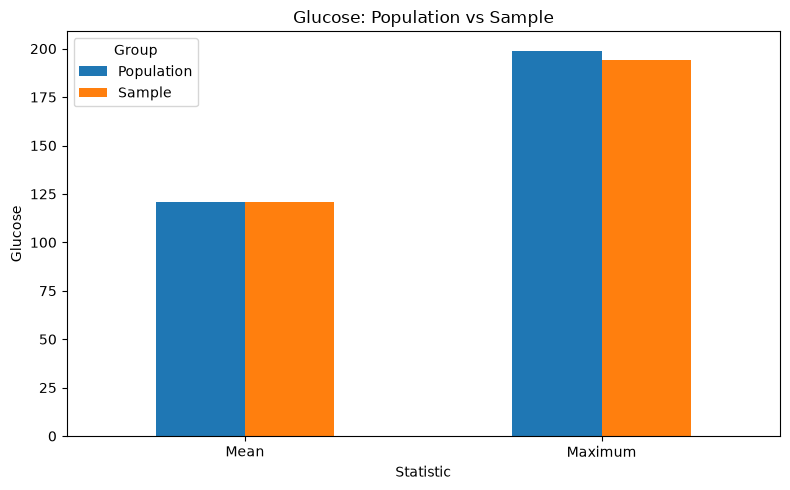

In [5]:
comparison_chart = comparison.set_index("Statistic")

ax = comparison_chart.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Glucose: Population vs Sample")
plt.xlabel("Statistic")
plt.ylabel("Glucose")
plt.legend(title="Group")
plt.tight_layout()
plt.show()

In [9]:
print(f"Population Mean: {pop_mean:.2f}")
print(f"Sample Mean: {sample_mean:.2f}")
print(f"Mean Difference: {sample_mean - pop_mean:.2f}\n")


print(f"Population Maximum: {pop_max:.2f}")
print(f"Sample Maximum: {sample_max:.2f}")
print(f"Maximum Difference: {sample_max - pop_max:.2f}")

Population Mean: 120.89
Sample Mean: 121.00
Mean Difference: 0.11

Population Maximum: 199.00
Sample Maximum: 194.00
Maximum Difference: -5.00


Question 2-(b)

In [10]:
pop_bmi_98 = df["BMI"].quantile(0.98)
sample_bmi_98 = sample_df["BMI"].quantile(0.98)

print(f"Population BMI 98th Percentile: {pop_bmi_98:.2f}")
print(f"Sample BMI 98th Percentile: {sample_bmi_98:.2f}")

Population BMI 98th Percentile: 47.53
Sample BMI 98th Percentile: 42.04


In [11]:
bmi_comparison = pd.DataFrame({
    "Group": ["Population", "Sample"],
    "BMI_98th_Percentile": [pop_bmi_98, sample_bmi_98]
})

bmi_comparison

,Group,BMI_98th_Percentile
0,Population,47.526
1,Sample,42.036


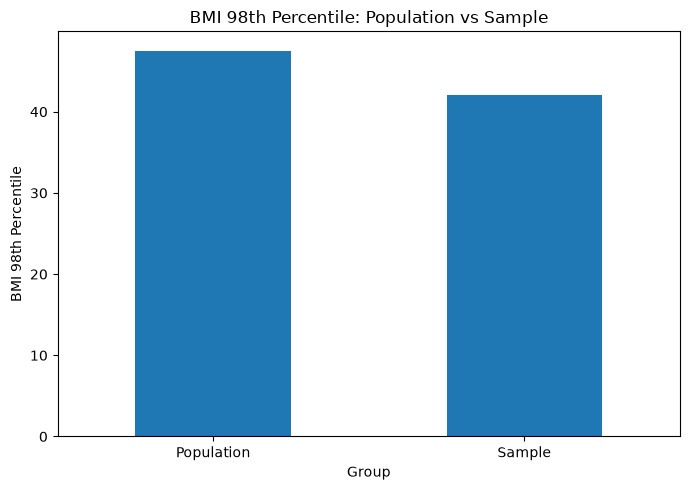

In [12]:
ax = bmi_comparison.plot(
    x="Group",
    y="BMI_98th_Percentile",
    kind="bar",
    figsize=(7, 5),
    rot=0,
    legend=False
)

plt.title("BMI 98th Percentile: Population vs Sample")
plt.xlabel("Group")
plt.ylabel("BMI 98th Percentile")
plt.tight_layout()
plt.show()

In [13]:
bmi_difference = sample_bmi_98 - pop_bmi_98

print(f"Population: {pop_bmi_98:.2f}")
print(f"Sample: {sample_bmi_98:.2f}")
print(f"Difference: {bmi_difference:.2f}")

Population: 47.53
Sample: 42.04
Difference: -5.49


Question 2-(c)

In [14]:
np.random.seed(26)

n_bootstrap = 500
sample_size = 150

bootstrap_means = []
bootstrap_stds = []
bootstrap_percentiles = []

for i in range(n_bootstrap):
    bootstrap_sample = df["BloodPressure"].sample(
        n=sample_size,
        replace=True,
    )
    bootstrap_means.append(bootstrap_sample.mean())
    bootstrap_stds.append(bootstrap_sample.std())
    bootstrap_percentiles.append(bootstrap_sample.quantile(0.95))

print("Number of bootstrap samples:", len(bootstrap_means))


Number of bootstrap samples: 500


In [15]:
pop_bp_mean = df["BloodPressure"].mean()
pop_bp_std = df["BloodPressure"].std(ddof=0)
pop_bp_percentile = df["BloodPressure"].quantile(0.95)

print(f"Population Mean: {pop_bp_mean:.2f}")
print(f"Population Standard Deviation: {pop_bp_std:.2f}")
print(f"Population 95th Percentile: {pop_bp_percentile:.2f}")

Population Mean: 69.11
Population Standard Deviation: 19.34
Population 95th Percentile: 90.00


In [17]:
rng = np.random.default_rng(26)

bootstrap_means = []
bootstrap_stds = []
bootstrap_percentiles = []

for i in range(n_bootstrap):
    bootstrap_sample = rng.choice(
        df["BloodPressure"].to_numpy(),
        size=sample_size,
        replace=True
    )

    bootstrap_means.append(np.mean(bootstrap_sample))
    bootstrap_stds.append(np.std(bootstrap_sample, ddof=0))
    bootstrap_percentiles.append(
        np.percentile(bootstrap_sample, 95)
    )

In [18]:
bootstrap_mean = np.mean(bootstrap_means)
bootstrap_std = np.mean(bootstrap_stds)
bootstrap_percentile = np.mean(bootstrap_percentiles)

bp_comparison = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Standard Deviation",
        "95th Percentile"
    ],
    "Population": [
        pop_bp_mean,
        pop_bp_std,
        pop_bp_percentile
    ],
    "Bootstrap Average": [
        bootstrap_mean,
        bootstrap_std,
        bootstrap_percentile
    ]
})

bp_comparison

,Statistic,Population,Bootstrap Average
0,Mean,69.105469,69.026147
1,Standard Deviation,19.343202,19.228198
2,95th Percentile,90.000000,91.075100


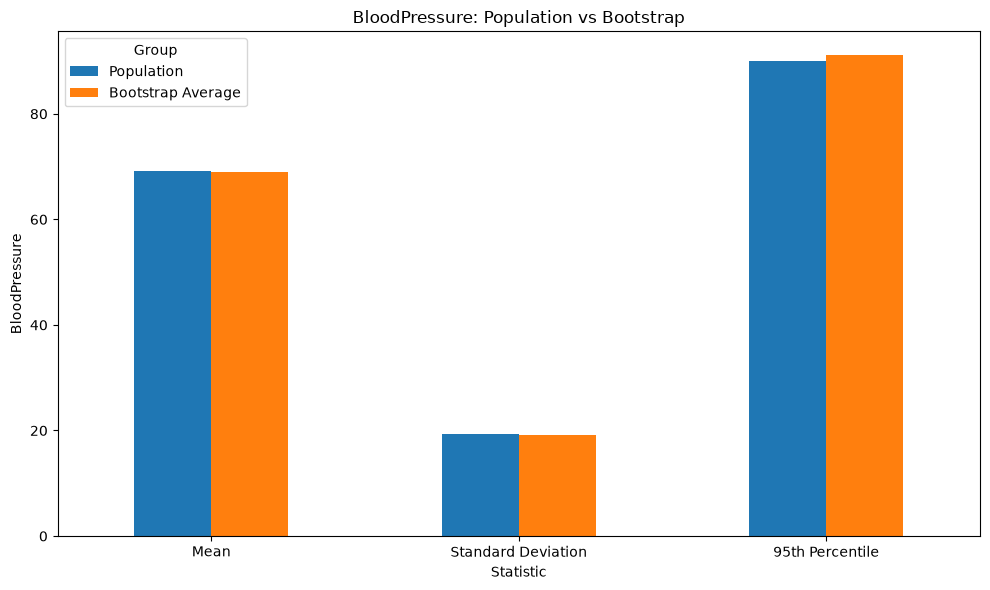

In [19]:
ax = bp_comparison.set_index("Statistic").plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

plt.title("BloodPressure: Population vs Bootstrap")
plt.xlabel("Statistic")
plt.ylabel("BloodPressure")
plt.legend(title="Group")
plt.tight_layout()
plt.show()

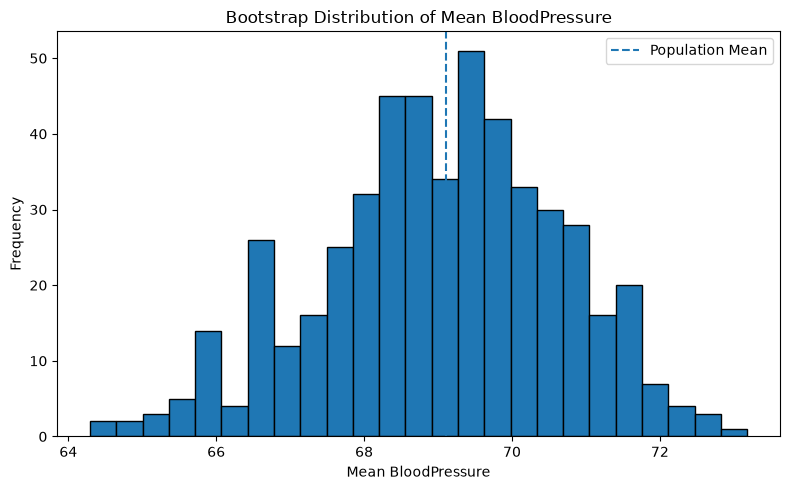

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(
    bootstrap_means,
    bins=25,
    edgecolor="black"
)

plt.axvline(
    pop_bp_mean,
    linestyle="--",
    label="Population Mean"
)

plt.title("Bootstrap Distribution of Mean BloodPressure")
plt.xlabel("Mean BloodPressure")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
bp_comparison["Difference"] = (
    bp_comparison["Bootstrap Average"]
    - bp_comparison["Population"]
)

print(bp_comparison.round(2))

            Statistic  Population  Bootstrap Average  Difference
0                Mean       69.11              69.03       -0.08
1  Standard Deviation       19.34              19.23       -0.12
2     95th Percentile       90.00              91.08        1.08


Q2-(c): Bootstrap Analysis — Findings

A total of 500 bootstrap samples were generated using sampling with replacement, with 150 observations in each sample.

The population mean of BloodPressure was 69.11, while the average bootstrap mean was 69.03, showing a difference of -0.08.

The population standard deviation was 19.34, compared to the average bootstrap standard deviation of 19.23, with a difference of -0.12.

The population 95th percentile was 90.00, while the average bootstrap 95th percentile was 91.08, showing a difference of 1.08.

Overall, the average bootstrap statistics were close to the corresponding population statistics. These results suggest that bootstrap sampling provided similar estimates of the population mean, standard deviation, and 95th percentile in this analysis.